In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score

# Chargement des données
features = pd.read_csv("../data/raw/elliptic_txs_features.csv", header=None)
edges    = pd.read_csv("../data/raw/elliptic_txs_edgelist.csv")
classes  = pd.read_csv("../data/raw/elliptic_txs_classes.csv")

# Renommage des colonnes
features.columns = ["txId", "time_step"] + [f"f{i}" for i in range(1, 166)]

In [2]:
# 1. Fusionner les features et les classes
df = features.merge(classes, on="txId", how="left")

# 2. Filtrer : on ne garde QUE les illicites (1) et licites (2)
df_labeled = df[df["class"].isin(["1", "2"])].copy()

# 3. Convertir la classe en binaire (1 = illicite, 0 = licite)
df_labeled["target"] = df_labeled["class"].apply(lambda x: 1 if x == "1" else 0)

# 4. Split Temporel (Train: time steps 0 à 34, Test: time steps 35 à 49)
train_df = df_labeled[df_labeled["time_step"] <= 34]
test_df  = df_labeled[df_labeled["time_step"] > 34]

# 5. Séparer les features (X) et la cible (y)
X_train = train_df.drop(columns=["txId", "class", "target"])
y_train = train_df["target"]

X_test = test_df.drop(columns=["txId", "class", "target"])
y_test = test_df["target"]

print(f"Taille Train : {X_train.shape[0]} transactions")
print(f"Taille Test  : {X_test.shape[0]} transactions")
print(f"Ratio fraude Train : {y_train.mean():.2%}")
print(f"Ratio fraude Test  : {y_test.mean():.2%}")

Taille Train : 29894 transactions
Taille Test  : 16670 transactions
Ratio fraude Train : 11.58%
Ratio fraude Test  : 6.50%


In [3]:
def evaluate_model(model, model_name, X_tr, y_tr, X_te, y_te):
    # Entraînement
    model.fit(X_tr, y_tr)
    # Prédiction
    y_pred = model.predict(X_te)
    
    print(f"\n{'='*40}")
    print(f"📊 MODÈLE : {model_name}")
    print(f"{'='*40}")
    
    # Métriques clés (on se concentre sur la classe 1 = illicite)
    print(classification_report(y_te, y_pred, target_names=["Licite (0)", "Illicite (1)"]))
    
    # Matrice de confusion
    cm = confusion_matrix(y_te, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=["Prédit Licite", "Prédit Illicite"], 
                yticklabels=["Vrai Licite", "Vrai Illicite"])
    plt.title(f"Matrice de confusion - {model_name}")
    plt.show()

# On définit class_weight='balanced' pour dire au modèle de faire attention aux illicites (qui sont rares)


📊 MODÈLE : Logistic Regression
              precision    recall  f1-score   support

  Licite (0)       0.99      0.75      0.85     15587
Illicite (1)       0.19      0.86      0.31      1083

    accuracy                           0.75     16670
   macro avg       0.59      0.81      0.58     16670
weighted avg       0.94      0.75      0.82     16670



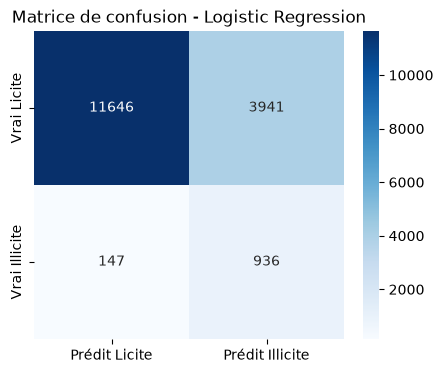


📊 MODÈLE : Random Forest
              precision    recall  f1-score   support

  Licite (0)       0.98      1.00      0.99     15587
Illicite (1)       0.91      0.72      0.81      1083

    accuracy                           0.98     16670
   macro avg       0.95      0.86      0.90     16670
weighted avg       0.98      0.98      0.98     16670



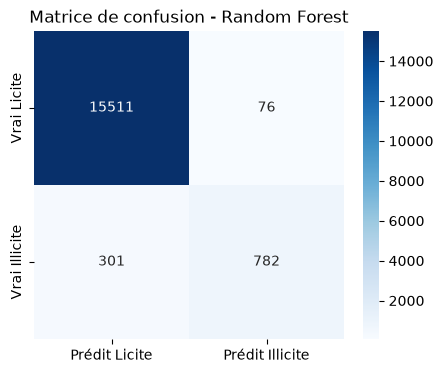


📊 MODÈLE : MLP (Réseau de neurones)
              precision    recall  f1-score   support

  Licite (0)       0.96      0.99      0.98     15587
Illicite (1)       0.73      0.47      0.57      1083

    accuracy                           0.95     16670
   macro avg       0.85      0.73      0.77     16670
weighted avg       0.95      0.95      0.95     16670



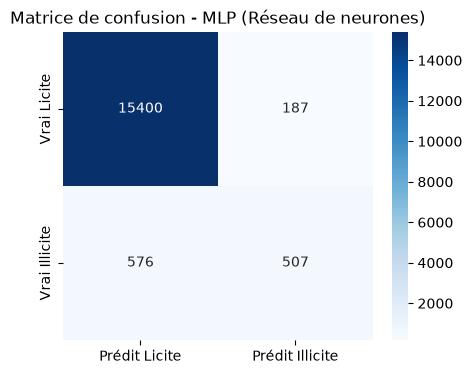

In [4]:
# 1. Logistic Regression (Modèle simple et rapide)
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
evaluate_model(lr, "Logistic Regression", X_train, y_train, X_test, y_test)

# 2. Random Forest (Modèle très robuste)
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
evaluate_model(rf, "Random Forest", X_train, y_train, X_test, y_test)

# 3. MLP (Réseau de neurones simple)
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
evaluate_model(mlp, "MLP (Réseau de neurones)", X_train, y_train, X_test, y_test)

## 📝 Synthèse de l'Étape 2 : Baselines ML Classiques

Cette section résume l'analyse des performances des trois modèles de Machine Learning classiques (Logistic Regression, Random Forest, MLP) entraînés sans utiliser la structure du graphe.

### 1. Compréhension des Métriques
Avant d'analyser les résultats, voici le rôle des métriques principales (appliquées à la classe 1 = Illicite / Fraude) :
- **Precision (Précision)** : *"Quand le modèle crie à la fraude, a-t-il raison ?"* 
  → Une précision basse signifie beaucoup de **fausses alertes** (transactions licites bloquées par erreur).
- **Recall (Rappel)** : *"Parmi toutes les vraies fraudes, combien le modèle a-t-il réussi à en détecter ?"*
  → Un rappel bas signifie que le modèle laisse passer beaucoup de **criminels** (faux négatifs).
- **F1-score** : La moyenne harmonique entre la Précision et le Rappel. 
  → **C'est la métrique la plus importante pour nous**, car le dataset est très déséquilibré. Elle pénalise les modèles qui ont un score parfait dans une métrique mais catastrophique dans l'autre.
- **Support** : Le nombre réel de transactions de chaque classe dans le jeu de test.

### 2. Analyse des Résultats et Matrices de Confusion

| Modèle | Precision | Rappel | F1-Score | Analyse du comportement (Matrice de confusion) |
| :--- | :---: | :---: | :---: | :--- |
| **Logistic Regression** | 0.19 | 0.86 | **0.31** | **Le paranoïaque.** Il détecte 86% des fraudes, mais il génère énormément de fausses alertes (3941 transactions licites bloquées). Inutilisable en pratique. |
| **MLP (Réseau simple)** | 0.73 | 0.47 | **0.57** | **Le trop prudent.** Il a peur de se tromper. Il bloque peu de licites, mais il laisse passer plus de la moitié des fraudes (576 fraudes ratées). |
| **Random Forest** | 0.91 | 0.72 | **0.81** | **L'équilibré.** Excellent compromis. Très fiable (seulement 76 fausses alertes) et détecte 72% des fraudes. |

### 3. Conclusion et Modèle Gagnant

Le grand gagnant de cette phase de référence (Baseline) est le **Random Forest** avec un **F1-score de 0.81**. 

**Pourquoi c'est important pour la suite du projet ?**
Le Random Forest devient notre **"Boss final"** à battre. Il est très performant car il analyse parfaitement les 166 features de chaque transaction, *mais il est aveugle* : il ne voit pas les liens (les arêtes) entre les transactions.
L'objectif de la prochaine phase (le **GCN**) sera de faire mieux que 0.81 en exploitant le graphe. Si le GCN fait un F1-score supérieur, nous aurons prouvé scientifiquement que l'analyse des relations (le voisinage) apporte une valeur ajoutée dans la détection de la fraude.